# 09 · Fire outlook: one to three months ahead

> **What and why**
>
> - Fire agencies plan weeks ahead. They need to know if the coming months will be worse than normal.
> - For every country and state we give the chance that fire will be above normal 1, 2 and 3 months ahead.
> - We use only what is known at the end of the latest month: recent fire, recent rain, temperature, El Niño and the Indian Ocean Dipole.
> - We test it on blocks of years the model never saw and compare it with the normal chance (the Brier skill score).

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
import json
from matplotlib.colors import LogNorm, Normalize, TwoSlopeNorm
from fireharmony import climate as K, drivers as D
MODELS = REPO / 'models'
BORDERS = con.execute(f"SELECT ST_AsText(ST_Simplify(geom, 0.15)) AS w FROM ST_Read('{FE.ne_source('ne_10m_admin_0_countries')}')").df().w
from fireharmony import outlook as O
cv_all = pd.read_parquet(K.out('outlook_cv.parquet'))
cv = cv_all[cv_all.in_season]          # the outlook is issued and scored for fire season months only
now = pd.read_parquet(K.out('outlook.parquet'))
summary = json.loads((MODELS / 'outlook.json').read_text())
names = con.execute(f"SELECT kind, id, name FROM read_json_auto('{C.path('products') / 'v1.0' / 'areas.json'}')").df()
print(f"issued from {summary['issued_from']}, {summary['areas']:,} areas")

issued from 2026-10, 1,443 areas


## 1. Skill on years the model never saw

The Brier score is the mean squared error of a probability. The Brier skill score compares it with always giving the normal chance of that area and month: 0 means no better, 1 is perfect.

The outlook is given for months of the fire season only: a target month whose normal fire is at least a fifth of an average month. Outside the season, above normal turns on a handful of hotspots, and the chances were too sure of themselves. Areas whose fire is mostly on barren land or ice (gas flares and lava, for example in Svalbard, Iceland and the Algerian Sahara) get no outlook.

In [2]:
pd.DataFrame(summary['score']).T

,n,brier,brier_clim,bss
lead 1,322344.0,0.2131,0.2886,0.2618
lead 2,322344.0,0.2339,0.2886,0.1894
lead 3,322344.0,0.2410,0.2886,0.1650
all,967032.0,0.2293,0.2886,0.2054
test 2022 to 2025,161172.0,0.2140,0.2828,0.2431
"all months, fire season or not",1491264.0,0.2379,0.2903,0.1806


## 2. Can the chances be trusted?

When the outlook says 70%, fire should be above normal in about 7 of 10 such cases. Each point groups forecasts with similar chances.

lead,1,2,3
id,,,
Africa,0.108,0.075,0.085
North America,0.206,0.129,0.110
Asia,0.218,0.159,0.154
Oceania,0.266,0.132,0.107
Europe,0.318,0.245,0.224
South America,0.321,0.216,0.185


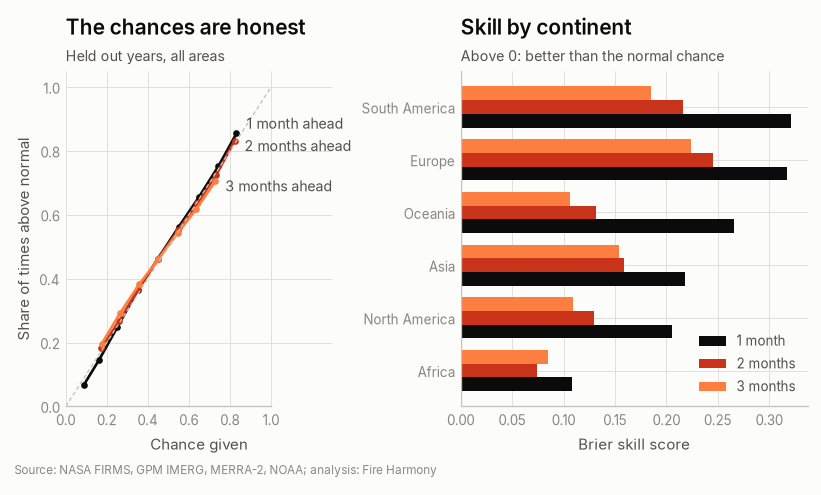

In [3]:
fig, axes = plt.subplots(1, 2, figsize=fh.SIZE['full'], gridspec_kw={'width_ratios': [1, 1.3]})
ax = axes[0]
bins = np.linspace(0, 1, 11)
ends = []
for L, col in zip(O.LEADS, [fh.INK, fh.EMBER[5], fh.EMBER[3]]):
    g = cv[cv.lead == L]
    b = pd.cut(g.p, bins, include_lowest=True)
    r = g.groupby(b, observed=True).agg(p=('p', 'mean'), o=('above', 'mean'), n=('p', 'size'))
    r = r[r.n >= 200]
    ax.plot(r.p, r.o, marker='o', ms=3, color=col, lw=1.6)
    ends.append((r.p.iloc[-1], r.o.iloc[-1], f'{L} month ahead' if L == 1 else f'{L} months ahead'))
fh.label_ends(ax, ends, gap=0.07)
ax.plot([0, 1], [0, 1], color=fh.BASELINE, lw=0.8, ls=(0, (3, 2)))
ax.set_xlim(0, 1.3); ax.set_ylim(0, 1.05); ax.set_xlabel('Chance given'); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0]); ax.spines['bottom'].set_bounds(0, 1); ax.set_ylabel('Share of times above normal')
fh.clean(ax, grid_axis='both')
fh.title(ax, 'The chances are honest', 'Held out years, all areas')
ax = axes[1]
cont = cv[cv.kind == 'continent'].groupby(['id', 'lead']).apply(lambda g: O.brier(g)['bss'], include_groups=False).unstack('lead')
cont = cont.drop(index=[i for i in cont.index if i in ('Antarctica', 'Seven seas (open ocean)')], errors='ignore').sort_values(1)
y = np.arange(len(cont))
for k, (L, col) in enumerate(zip(O.LEADS, [fh.INK, fh.EMBER[5], fh.EMBER[3]])):
    ax.barh(y + (k - 1) * 0.26, cont[L], 0.26, color=col, label=f'{L} month' + ('s' if L > 1 else ''))
ax.set_yticks(y, cont.index); ax.axvline(0, color=fh.BASELINE, lw=0.8)
fh.clean(ax, grid_axis='x'); ax.legend(frameon=False, fontsize=8, loc='lower right'); ax.set_xlabel('Brier skill score')
fh.title(ax, 'Skill by continent', 'Above 0: better than the normal chance')
fh.source(fig, 'Source: NASA FIRMS, GPM IMERG, MERRA-2, NOAA; analysis: Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.035, 1, 1))
fh.save(fig, FIG / 'fig17_outlook_skill')
cont.round(3)

## 3. Skill in the places we feature

In [4]:
feat = [('country', 'IDN'), ('country', 'MYS'), ('state', 'IDN-1931'), ('state', 'IDN-492'), ('country', 'BRA'), ('country', 'AUS'), ('country', 'CAN'), ('country', 'USA')]
rows = []
for kind, id_ in feat:
    g = cv[(cv.kind == kind) & (cv.id == id_)]
    rows.append({'area': names.set_index(['kind', 'id']).name.get((kind, id_), id_), **{f'{L} month': O.brier(g[g.lead == L])['bss'] for L in O.LEADS}})
pd.DataFrame(rows).set_index('area').round(3)

,1 month,2 month,3 month
area,,,
Indonesia,0.534,0.410,0.355
Malaysia,0.483,0.393,0.355
"Kalimantan Tengah, Indonesia",0.578,0.465,0.347
"Riau, Indonesia",0.460,0.407,0.422
Brazil,0.451,0.339,0.284
Australia,0.263,0.133,0.110
Canada,0.099,0.103,0.089
United States of America,0.169,0.095,0.097


## 4. What the model uses

The share of the total gain of each input in the final model.

In [5]:
pd.Series(summary['feature_gain_pct']).rename('share of gain, %').to_frame()

,"share of gain, %"
y0,41.6
target_share,9.6
dmi,8.9
oni,8.7
y1,6.2
abs_lat,5.8
lead,5.5
y2,3.5
target_mo_sin,2.6
t2m_z_prev,2.1


## 5. The outlook now

In [6]:
sel = now.merge(names, on=['kind', 'id'], how='left')
sel = sel[sel.set_index(['kind', 'id']).index.isin(feat)]
sel.pivot_table(index='name', columns='lead', values=['p', 'p_clim']).round(2)

p             p_clim            
lead                             1     2     3      1     2     3
name                                                             
Australia                     0.23  0.31  0.34   0.46  0.46  0.46
Brazil                        0.36  0.42  0.44   0.46  0.46  0.46
Canada                        0.21   NaN   NaN   0.50   NaN   NaN
Indonesia                     0.84   NaN   NaN   0.46   NaN   NaN
Kalimantan Tengah, Indonesia  0.80   NaN   NaN   0.46   NaN   NaN
Malaysia                      0.18   NaN  0.31   0.46   NaN  0.46
Riau, Indonesia                NaN   NaN  0.20    NaN   NaN  0.50
United States of America      0.36  0.39  0.36   0.46  0.50  0.50

> **Key findings**
>
> - In the fire season months where it is given, the outlook beats the normal chance by 26% one month ahead, 19% two months ahead and 17% three months ahead (Brier skill score, years the model never saw). On the latest years (2022 to 2025) it scores 0.24 over the three leads.
> - It works almost everywhere: more than 99% of areas beat the normal chance at every lead.
> - Skill is highest where El Niño and drought drive fire: one month ahead it is 0.58 in Central Kalimantan, 0.53 in Indonesia, 0.48 in Malaysia and 0.45 in Brazil. It is lowest in Africa (0.11), where the savanna burns in much the same way every year.
> - The chances can be trusted across the whole range: when the outlook says 74%, fire comes out above normal 74% of the time, and when it says 17%, 15% of the time.
> - This needed one rule: the outlook is for months of the fire season only (a month whose normal fire is at least a fifth of an average month). In the deep off season, above normal turns on a handful of hotspots, and there the chances were too sure of themselves.
> - Recent fire is the strongest clue (42% of the gain), then how much of the year's fire the target month holds, the Indian Ocean Dipole and El Niño (9% each).
> - From the data to October 2026: Indonesia has an 84% chance of above normal fire in November (the normal chance is 46%), and Central Kalimantan 80%. Malaysia (18%) is likely to stay below normal.